In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
def count_parameters(input_size, hidden_layers, output_size=1):
    sizes = [input_size] + hidden_layers + [output_size]

    total = 0
    for i in range(len(sizes) - 1):
        total += sizes[i] * sizes[i + 1]  # Weights
        total += sizes[i + 1]            # Biases

    return total


# Architecture, hidden layers, best validation MAE
experiments = [
    ("32-32", [32, 32], 6.38),
    ("4", [4], 16.58),
    ("8", [8], 21.49),
    ("16", [16], 21.42),
    ("32", [32], 10.76),
    ("64", [64], 21.36),
    ("8-8", [8, 8], 8.18),
    ("16-16", [16, 16], 6.94),
    ("32-16", [32, 16], 6.29),
    ("32-64", [32, 64], 5.93),
    ("64-64", [64, 64], 5.69),
    ("64-128", [64,128], 5.85)
]

results = []

for name, layers, val_mae in experiments:
    params = count_parameters(5, layers)

    results.append({
        "Architecture": name,
        "Parameters": params,
        "Validation MAE": val_mae
    })

results_df = pd.DataFrame(results)

# Sort by parameter count
results_df = results_df.sort_values("Parameters").reset_index(drop=True)

display(results_df)

,Architecture,Parameters,Validation MAE
0,4,29,16.58
1,8,57,21.49
2,16,113,21.42
3,8-8,129,8.18
4,32,225,10.76
5,16-16,385,6.94
6,64,449,21.36
7,32-16,737,6.29
8,32-32,1281,6.38
9,32-64,2369,5.93


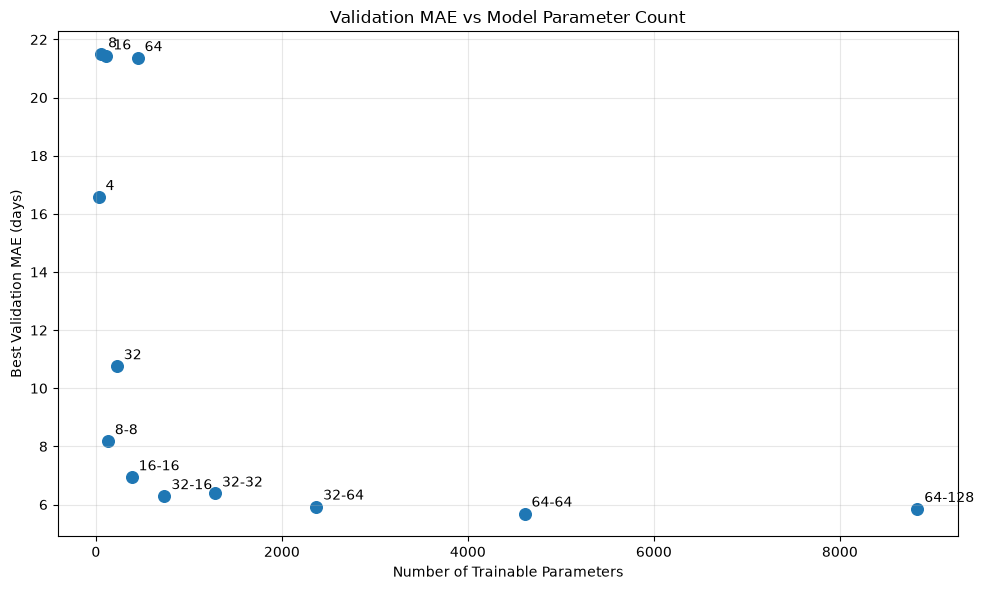

In [5]:
plt.figure(figsize=(10, 6))

plt.scatter(
    results_df["Parameters"],
    results_df["Validation MAE"],
    s=70
)

# Annotate each point with its architecture
for _, row in results_df.iterrows():
    plt.annotate(
        row["Architecture"],
        (row["Parameters"], row["Validation MAE"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Number of Trainable Parameters")
plt.ylabel("Best Validation MAE (days)")
plt.title("Validation MAE vs Model Parameter Count")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
architecture = [5, 32, 32, 32, 16, 1]
layer_names = [
    "Input → Hidden 1",
    "Hidden 1 → Hidden 2",
    "Hidden 2 → Hidden 3",
    "Hidden 3 → Hidden 4",
    "Hidden 4 → Output"
]

architecture = [5, 64, 64, 1]
layer_names = [
    "Input → Hidden 1",
    "Hidden 1 → Hidden 2",
    "Hidden 2 → Output"
]

In [ ]:
layer_data = []

for i in range(len(architecture) - 1):
    inputs = architecture[i]
    outputs = architecture[i + 1]

    weights = inputs * outputs
    biases = outputs
    params = weights + biases

    layer_data.append({
        "Layer": layer_names[i],
        "Weights": weights,
        "Biases": biases,
        "Parameters": params,
        "FP32 Memory (bytes)": params * 4,
        "MACs": weights
    })

layer_df = pd.DataFrame(layer_data)

display(layer_df)

print("Total parameters:", layer_df["Parameters"].sum())
print("Total FP32 memory (bytes):", layer_df["FP32 Memory (bytes)"].sum())
print("Total MACs:", layer_df["MACs"].sum())

,Layer,Weights,Biases,Parameters,FP32 Memory (bytes),MACs
0,Input → Hidden 1,160,32,192,768,160
1,Hidden 1 → Hidden 2,1024,32,1056,4224,1024
2,Hidden 2 → Hidden 3,512,16,528,2112,512
3,Hidden 3 → Hidden 4,256,16,272,1088,256
4,Hidden 4 → Output,16,1,17,68,16


Total parameters: 2065
Total FP32 memory (bytes): 8260
Total MACs: 1968


In [11]:
model_comparison = pd.DataFrame([
    {
        "Architecture": "Linear Regression",
        "Parameters": None,
        "Validation MAE": 27.70
    },
    {
        "Architecture": "32-32",
        "Parameters": count_parameters(5, [32, 32]),
        "Validation MAE": 6.38
    },
    {
        "Architecture": "32-64",
        "Parameters": count_parameters(5, [32, 64]),
        "Validation MAE": 5.93
    },
    {
        "Architecture": "64-64",
        "Parameters": count_parameters(5, [64, 64]),
        "Validation MAE": 5.69
    },
    {
        "Architecture": "32-32-16-16",
        "Parameters": count_parameters(5, [32, 32, 16, 16]),
        "Validation MAE": 5.71
    },
    {
        "Architecture": "32-32-32-16",
        "Parameters": count_parameters(5, [32, 32, 32, 16]),
        "Validation MAE": 5.60
    }, 
    {
        "Architecture": "64-64-16",
        "Parameters": count_parameters(5, [64, 64, 16]),
        "Validation MAE": 5.71
    }
])

display(model_comparison)

,Architecture,Parameters,Validation MAE
0,Linear Regression,NaN,27.70
1,32-32,1281.0,6.38
2,32-64,2369.0,5.93
3,64-64,4609.0,5.69
4,32-32-16-16,2065.0,5.71
5,32-32-32-16,2849.0,5.60
6,64-64-16,5601.0,5.71


In [13]:
selected_architecture = [32, 32, 32, 16]
selected_params = count_parameters(5, selected_architecture)
expected_mae = 5.60  # Best observed validation MAE

print("Selected architecture: 5 → 32 → 32 → 16 → 16 → 1")
print("Parameter count:", selected_params)
print("FP32 weight and bias storage:", selected_params * 4, "bytes")
print("INT8 theoretical weight storage:", selected_params, "bytes")
print("Expected MAE on unseen readings:", expected_mae, "days")

Selected architecture: 5 → 32 → 32 → 16 → 16 → 1
Parameter count: 2849
FP32 weight and bias storage: 11396 bytes
INT8 theoretical weight storage: 2849 bytes
Expected MAE on unseen readings: 5.6 days
